# S6E11 Starter: Predicting Credit Card Fraud
**Queen Mary ML Society · Kaggle Playground, November 2026**

**Goal:** predict the probability that each transaction is fraud (`is_fraud`).
**Metric:** ROC AUC, so submit **probabilities**, not 0/1 labels.
**Deadline:** 30 November 2026, 23:59 UTC.

What this notebook does:
1. Load the data
2. Look at the target (how rare is fraud?)
3. Find which features carry signal
4. Train a LightGBM baseline with 5-fold cross-validation
5. See why probabilities matter for AUC
6. Write `submission.csv`

Once you've run it top to bottom, you'll have a working submission. Then make it better (ideas at the end).

## 1. Load the data

In [1]:
# --- Import the libraries we need ---
import os                      # lets us check which folders exist on this computer
import numpy as np             # fast maths on arrays of numbers
import pandas as pd            # tables of data (DataFrames)
import lightgbm as lgb         # the model: gradient-boosted decision trees
from sklearn.model_selection import StratifiedKFold   # splits data into folds, keeping the fraud rate equal in each
from sklearn.metrics import roc_auc_score             # the competition metric (ROC AUC)

# Where the csv files live: the Kaggle folder if we're on Kaggle, otherwise the folder this notebook is in
DATA = "/kaggle/input/playground-series-s6e11/" if os.path.exists("/kaggle/input") else "./"

train = pd.read_csv(DATA + "train.csv")              # training data: features AND the answer (is_fraud)
test = pd.read_csv(DATA + "test.csv")                # test data: features only, we must predict is_fraud
sub = pd.read_csv(DATA + "sample_submission.csv")    # a template showing the format Kaggle expects

print("train:", train.shape, " test:", test.shape)   # .shape = (number of rows, number of columns)
train.head()                                         # show the first 5 rows so we can see what the data looks like

train: (699960, 26)  test: (299984, 25)


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [2]:
# .isna() marks every empty cell as True; .sum().sum() counts them across all columns
print("missing in train:", train.isna().sum().sum(), " missing in test:", test.isna().sum().sum())
train.dtypes.value_counts()   # how many columns there are of each type (numbers, text, True/False)

missing in train: 0  missing in test: 0


int64      8
float64    7
bool       6
str        5
Name: count, dtype: int64

## 2. The target: fraud is rare
This is the most important thing to understand about this dataset.

In [3]:
rate = train["is_fraud"].mean()   # is_fraud is 0 or 1, so its average is the fraction of rows that are fraud
print(f"Fraud rate: {rate:.2%}  (about 1 in {1/rate:.0f} transactions)")   # show it as a percentage and as "1 in N"
print(f"A model that always says 'not fraud' gets {1-rate:.1%} accuracy and is useless.")   # why accuracy misleads
print("That's why the metric is ROC AUC, not accuracy.")

Fraud rate: 1.67%  (about 1 in 60 transactions)
A model that always says 'not fraud' gets 98.3% accuracy and is useless.
That's why the metric is ROC AUC, not accuracy.


## 3. Which features carry signal?
**Yes/no flags:** compare the fraud rate when the flag is true vs false.

In [4]:
TARGET = "is_fraud"   # the name of the column we are trying to predict

# Collect every True/False column (the "risk flags")
flags = [c for c in train.columns if train[c].dtype == bool]

# Build a small table with one row per flag
flag_table = pd.DataFrame({
    "fraud rate if True": [train.loc[train[c], TARGET].mean() for c in flags],    # fraud rate among rows where the flag is True
    "fraud rate if False": [train.loc[~train[c], TARGET].mean() for c in flags],  # fraud rate among rows where it is False (~ means "not")
    "% of rows True": [train[c].mean() for c in flags],                           # how often the flag is True at all
}, index=flags)                                                                   # label each row with the flag's name

# Lift = how many times higher than the overall fraud rate (10 means 10x more fraud than usual)
flag_table["lift"] = flag_table["fraud rate if True"] / rate

# Show the table, strongest flag first, rounded to 3 decimal places
flag_table.sort_values("lift", ascending=False).style.format("{:.3f}")

,fraud rate if True,fraud rate if False,% of rows True,lift
ip_country_mismatch,0.165,0.014,0.016,9.878
is_ai_generated_scam_attempt,0.152,0.016,0.003,9.116
billing_shipping_mismatch,0.130,0.015,0.013,7.778
is_foreign_transaction,0.126,0.015,0.017,7.529
used_vpn,0.065,0.015,0.034,3.922
is_new_merchant,0.047,0.011,0.152,2.835


**Numeric features:** how well does each one *on its own* rank fraud above non-fraud?
AUC 0.5 = random, 1.0 = perfect. (We take max(AUC, 1−AUC) so features that point the "other way" also count.)

In [5]:
# All numeric columns, except the row id and the target itself
num_cols = [c for c in train.select_dtypes("number").columns if c not in ("id", TARGET)]

# Use each feature's raw values as if they were predictions, and score them with AUC
single_auc = {c: roc_auc_score(train[TARGET], train[c]) for c in num_cols}

# An AUC below 0.5 means "low values = fraud", which is just as useful, so flip it with 1 - AUC
single_auc = pd.Series({c: max(a, 1 - a) for c, a in single_auc.items()}).sort_values(ascending=False)

single_auc.round(3)   # show the result, best feature at the top

merchant_risk_score      0.749
velocity_score           0.711
cvv_retry_count          0.708
customer_age             0.625
txn_count_last_24h       0.620
hours_since_last_txn     0.568
amount_usd               0.545
prior_disputes           0.532
day_of_week              0.508
account_balance_usd      0.506
distance_from_home_km    0.504
card_age_months          0.502
time_of_day_hour         0.500
dtype: float64

**Categorical features:** fraud rate per category. Some barely matter (look at `channel`).

In [6]:
# All text columns (categories such as merchant_category or card_type)
cat_cols = list(train.select_dtypes(["object", "string"]).columns)

for c in cat_cols:                                   # go through the text columns one at a time
    fraud_by_cat = train.groupby(c)[TARGET].mean()   # fraud rate for each category in this column
    fraud_by_cat = fraud_by_cat.round(3).sort_values(ascending=False)   # round, and put the riskiest category first
    print(c, fraud_by_cat.to_dict(), "\n")           # print the column name and its fraud rates

merchant_category {'Gift Cards': 0.073, 'Crypto Exchange': 0.065, 'Gaming': 0.055, 'Electronics': 0.031, 'Streaming': 0.022, 'Travel': 0.019, 'Utilities': 0.014, 'Healthcare': 0.013, 'Fuel': 0.012, 'Groceries': 0.011, 'Online Retail': 0.011, 'Restaurants': 0.011} 

card_type {'Amex': 0.019, 'Visa': 0.017, 'RuPay': 0.017, 'Mastercard': 0.016, 'Discover': 0.015} 

auth_method {'No Authentication': 0.064, '3D Secure': 0.015, 'OTP': 0.014, 'PIN': 0.009, 'Biometric': 0.005} 

channel {'POS': 0.017, 'Online': 0.017, 'ATM': 0.016, 'In-App': 0.016, 'Contactless': 0.016} 

device_type {'ATM Machine': 0.017, 'Mac': 0.017, 'POS Terminal': 0.017, 'Smart Watch': 0.017, 'iPhone': 0.017, 'Tablet': 0.017, 'Android Phone': 0.016, 'Windows PC': 0.016} 



## 4. Baseline: LightGBM with 5-fold cross-validation
- **StratifiedKFold** keeps the 1.7% fraud rate the same in every fold.
- **Out-of-fold (OOF) predictions** give an honest score for the whole training set. Trust this more than the public leaderboard.
- Text and bool columns are converted to pandas `category`, which LightGBM handles natively.

In [7]:
# The columns the model is allowed to learn from: everything except the id and the answer
features = [c for c in train.columns if c not in ("id", TARGET)]

X = train[features].copy()        # training features (a copy, so the original table is untouched)
X_test = test[features].copy()    # test features, same columns in the same order

for c in cat_cols + flags:                    # for every text column and every True/False column...
    X[c] = X[c].astype("category")            # ...tell pandas it is a category, which LightGBM handles natively
    X_test[c] = pd.Categorical(X_test[c], categories=X[c].cat.categories)   # use the exact same categories in test

y = train[TARGET].astype(int)     # the answers as whole numbers: 0 = genuine, 1 = fraud

# Model settings
params = dict(
    n_estimators=2000,       # maximum number of trees (early stopping usually ends well before this)
    learning_rate=0.05,      # how much each new tree corrects the previous ones (smaller = slower but steadier)
    num_leaves=31,           # how complex each tree can be
    subsample=0.8,           # each tree sees a random 80% of the rows (helps prevent overfitting)
    subsample_freq=1,        # re-draw that random 80% for every tree
    colsample_bytree=0.8,    # each tree sees a random 80% of the columns
    random_state=42,         # fixed seed so results are the same every run
    verbose=-1,              # keep LightGBM quiet
)

# 5 folds: train on 4/5 of the data, check on the remaining 1/5, and rotate. Stratified = same fraud rate in each fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof = np.zeros(len(X))                          # "out-of-fold" predictions: one per training row, made by a model that never saw that row
test_pred = np.zeros(len(X_test))               # test predictions, averaged over the 5 models
importances = pd.Series(0.0, index=features)    # running average of how much each feature is used

for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):   # tr_idx = rows to train on, va_idx = rows to validate on
    model = lgb.LGBMClassifier(**params)                       # a fresh, untrained model with our settings
    model.fit(
        X.iloc[tr_idx], y.iloc[tr_idx],                        # learn from the training rows
        eval_set=[(X.iloc[va_idx], y.iloc[va_idx])],           # watch the score on the validation rows while training
        eval_metric="auc",                                     # the score to watch is AUC
        callbacks=[lgb.early_stopping(100, verbose=False)],    # stop if validation AUC hasn't improved for 100 trees
    )
    oof[va_idx] = model.predict_proba(X.iloc[va_idx])[:, 1]            # fraud probability for the validation rows ([:, 1] = the "fraud" column)
    test_pred += model.predict_proba(X_test)[:, 1] / skf.n_splits      # add this model's share (1/5) of the test prediction
    importances += pd.Series(model.feature_importances_, index=features) / skf.n_splits   # same idea for feature importance
    fold_auc = roc_auc_score(y.iloc[va_idx], oof[va_idx])              # score this fold
    print(f"Fold {fold}: AUC = {fold_auc:.4f}  (trees: {model.best_iteration_})")   # report the score and how many trees were kept

# Score all the out-of-fold predictions together: this is our cross-validation (CV) score
print(f"\nOverall OOF AUC: {roc_auc_score(y, oof):.4f}  <- your CV score, the number to beat")

/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: AUC = 0.9431  (trees: 222)


/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2: AUC = 0.9472  (trees: 301)


/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 3: AUC = 0.9503  (trees: 198)


/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4: AUC = 0.9464  (trees: 289)


/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5: AUC = 0.9413  (trees: 303)

Overall OOF AUC: 0.9456  <- your CV score, the number to beat


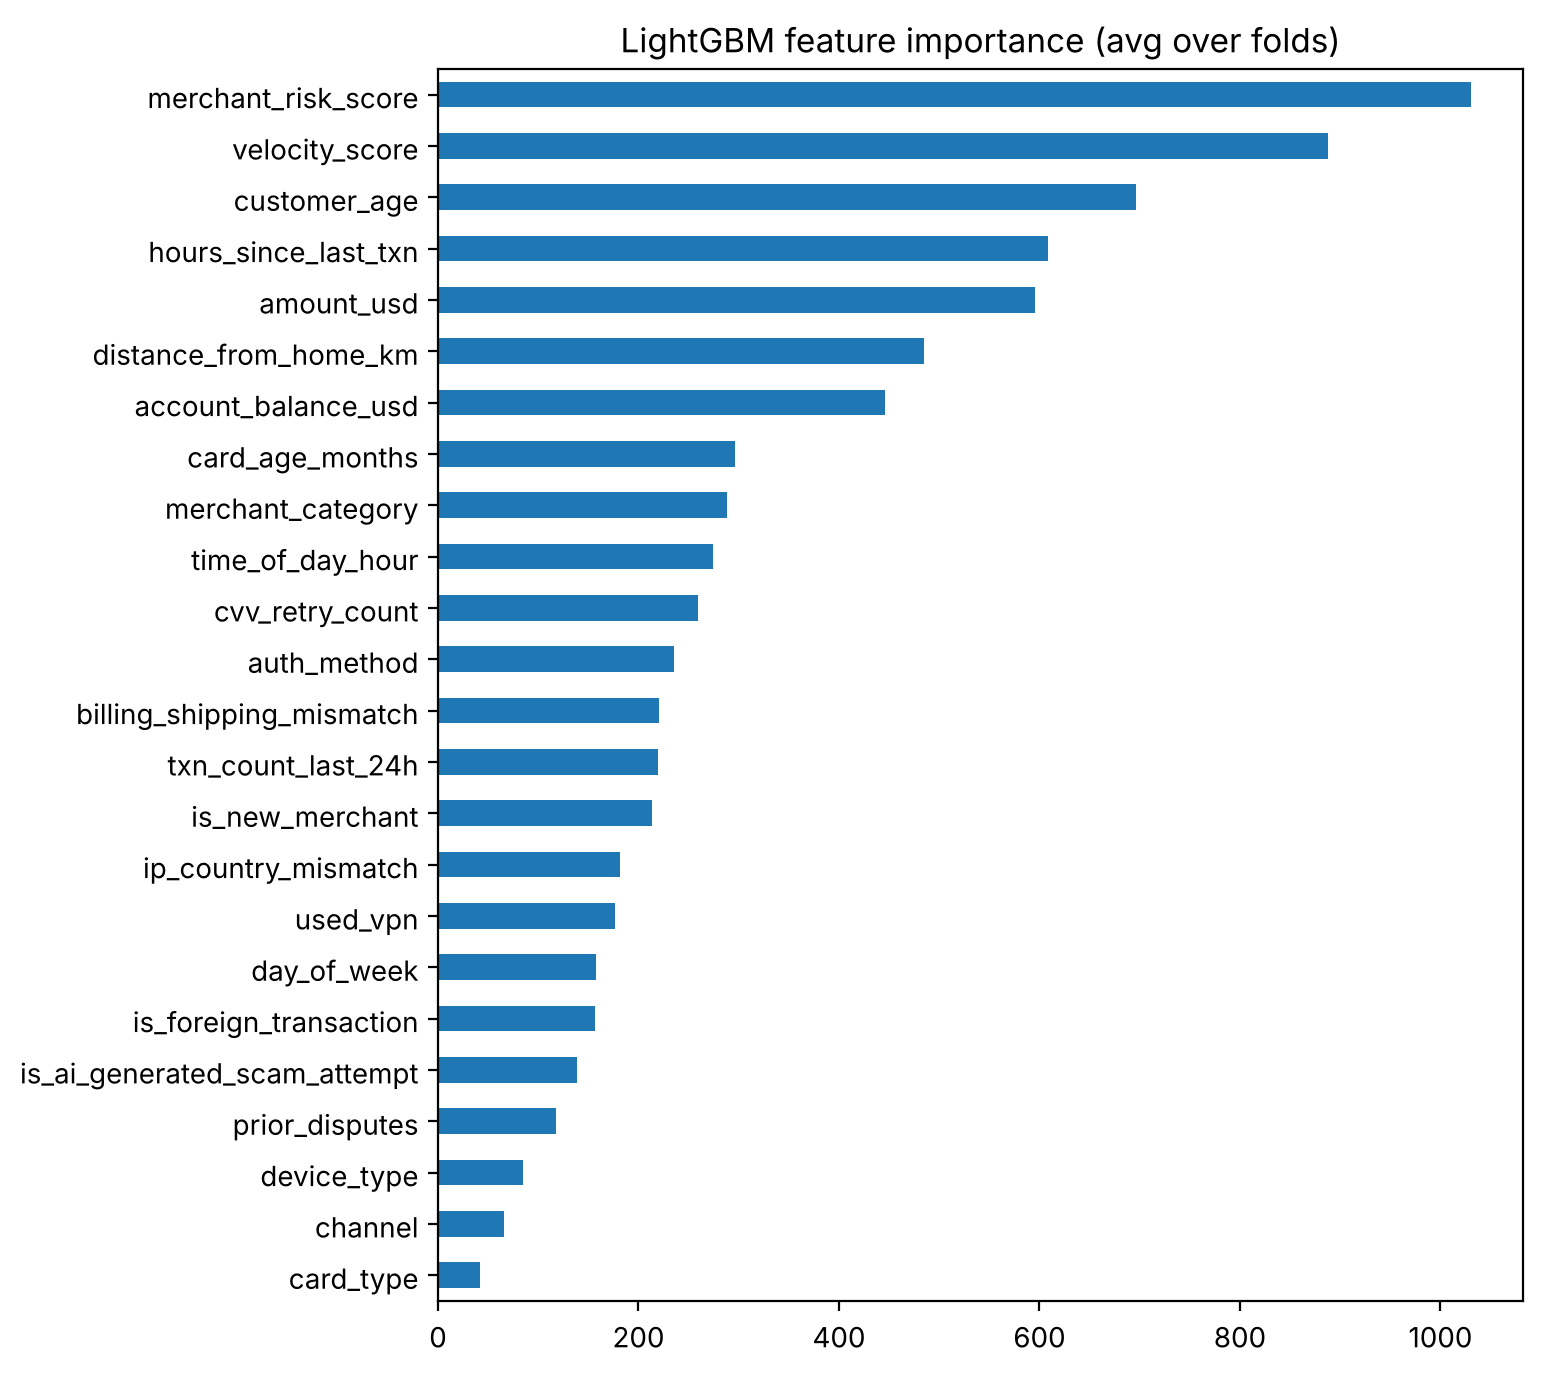

In [8]:
# Horizontal bar chart of feature importance, sorted so the most-used feature is at the top
importances.sort_values().plot.barh(figsize=(7, 8), title="LightGBM feature importance (avg over folds)");

## 5. Why probabilities matter
AUC scores the **ranking** of your predictions. If you round to 0/1 you throw that ranking away.

In [9]:
hard = (oof > 0.5).astype(int)   # round each probability: above 0.5 becomes 1 (fraud), otherwise 0
print(f"AUC with probabilities : {roc_auc_score(y, oof):.4f}")    # score the original probabilities
print(f"AUC with 0/1 labels    : {roc_auc_score(y, hard):.4f}")   # score the rounded 0/1 labels
print("Same model, same predictions. Rounding loses most of the score. Use predict_proba()[:, 1], not predict().")

AUC with probabilities : 0.9456
AUC with 0/1 labels    : 0.6522
Same model, same predictions. Rounding loses most of the score. Use predict_proba()[:, 1], not predict().


## 6. Write the submission

In [10]:
sub["is_fraud"] = test_pred                 # put our predicted probabilities into the template
sub.to_csv("submission.csv", index=False)   # save the file to upload (index=False = don't add an extra row-number column)
print(sub.shape)                            # check: should be (299984, 2)
sub.head()                                  # look at the first few rows before submitting

(299984, 2)


,id,is_fraud
0,699960,0.000347
1,699961,0.000237
2,699962,0.098647
3,699963,0.001574
4,699964,0.001486


## Next steps: how to climb the leaderboard
1. **Submit this first.** Get on the board, then improve.
2. **Feature engineering:** ratios like `amount_usd / account_balance_usd`, counts of risk flags per row, amount relative to the customer's typical spend.
3. **Add the original dataset.** This data was generated from *Credit Card Fraud Detection 2026*; appending the original rows to train often helps in Playground competitions.
4. **Try other models:** XGBoost, CatBoost (good with categoricals), or AutoGluon.
5. **Ensemble:** averaging the predictions of different models usually beats any single one.
6. **Track CV, not just the public LB:** the public leaderboard uses only part of the test set.

Share what works in the society channel!